# 01 Conhecer e validar os dados

Este notebook apresenta a base Home Credit e verifica a qualidade do recorte
que será utilizado no desafio: **20.000 solicitações, dez variáveis,
um identificador e o alvo**. Não treinamos modelos nem alteramos os CSVs aqui.

**Sequência:** 01 conhecer e validar → 02 limpar, normalizar e treinar →
03 propor a solução e a estratégia do Tech Challenge.

Os dados de origem são `application_train.csv` e
`HomeCredit_columns_description.csv`, já disponíveis em
`data/raw/home-credit-default-risk/`. As tabelas auxiliares da competição
não são necessárias. Execute as células de cima para baixo.

## 1 Ambiente e arquivos utilizados

Use o ambiente do projeto (`make notebook`) ou o Jupyter do Docker.
O notebook não faz download nem autenticação no Kaggle.

In [1]:
import sys
from pathlib import Path

from IPython.display import display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

from ml_prep_kit import (
    CSVDataLoader,
    DataValidator,
    HomeCreditData,
    VisualizationReporter,
)

In [2]:
raw_path = project_root / "data/raw/home-credit-default-risk"
loader = CSVDataLoader(raw_path)
preparation = HomeCreditData(sample_size=20_000, random_state=42)
validator = DataValidator()
reporter = VisualizationReporter()

## 2 Recorte escolhido e significado das variáveis

`SK_ID_CURR` serve para rastreabilidade e nunca será uma feature.
`TARGET = 1` indica dificuldade de pagamento; `0` representa os demais casos.
O dicionário não revela os limites de dias e parcelas usados para construir
esse alvo, portanto não o interpretaremos como inadimplência em 30 ou 90 dias.

A idade está em dias negativos, relativos à solicitação. A renda e a anuidade
não serão chamadas de valores mensais, anuais ou em reais sem confirmação
dessa informação na documentação da fonte.

Mantemos idade, renda, valor do crédito, anuidade, tipo de renda, escolaridade,
moradia, filhos, posse de carro e posse de imóvel. A seleção é fixa;
não faremos seleção de features usando resultados do conjunto de teste.

In [3]:
raw_df = loader.load(
    {"solicitacoes": "application_train.csv"},
    read_csv_kwargs={"usecols": preparation.source_columns},
)["solicitacoes"]
sample_df = preparation.sample(raw_df)
tables = {"origem": raw_df, "amostra": sample_df}
display(validator.summarize(tables))

,dataset,rows,columns,memory_mb
0,origem,307511,12,104.362791
1,amostra,20000,12,6.788032


In [4]:
dictionary = loader.load(
    {"dicionario": "HomeCredit_columns_description.csv"},
    read_csv_kwargs={"encoding": "cp1252"},
)["dicionario"]
display(
    validator.select_dictionary(
        dictionary, preparation.source_columns, table_pattern="application_{"
    )
)

,coluna,descrição,Special
0,SK_ID_CURR,ID of loan in our sample,NaN
1,TARGET,Target variable (1 - client with payment diffi...,NaN
4,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,CNT_CHILDREN,Number of children the client has,NaN
7,AMT_INCOME_TOTAL,Income of the client,NaN
8,AMT_CREDIT,Credit amount of the loan,NaN
9,AMT_ANNUITY,Loan annuity,NaN
12,NAME_INCOME_TYPE,"Clients income type (businessman, working, mat...",NaN
13,NAME_EDUCATION_TYPE,Level of highest education the client achieved,NaN


## 3 Amostragem e variável alvo

A amostra é estratificada por `TARGET`, com seed 42, e preserva aproximadamente
a proporção das classes. O segundo notebook repetirá exatamente essa seleção
antes de separar treino, validação, teste e produção simulada.

Esta visão caracteriza a base; as métricas do modelo serão calculadas
separadamente, sem ajustar o modelo a partir do teste ou da produção.

,dataset,target,count,percent
0,origem,0,282686,91.927118
1,origem,1,24825,8.072882
2,amostra,0,18385,91.925000
3,amostra,1,1615,8.075000


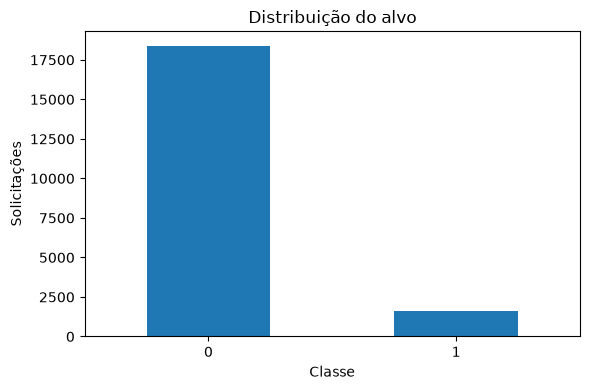

In [5]:
display(validator.compare_targets(tables, preparation.target))
_ = reporter.plot_target_counts(sample_df[preparation.target])

## 4 Tipos, ausências e duplicidades

Nulos não serão preenchidos durante a análise. Primeiro identificamos onde
existem e decidimos o tratamento. No treino, a anuidade ausente poderá ser
imputada pela mediana aprendida exclusivamente no conjunto de treinamento.

In [6]:
display(validator.describe_schema(tables))
display(validator.columns_with_missing_values(sample_df))
display(validator.duplicated_rows_by_table(tables))

,dataset,column,dtype,nulls,null_rate,unique_values
0,origem,SK_ID_CURR,int64,0,0.000000,307511
1,origem,TARGET,int64,0,0.000000,2
2,origem,FLAG_OWN_CAR,object,0,0.000000,2
3,origem,FLAG_OWN_REALTY,object,0,0.000000,2
4,origem,CNT_CHILDREN,int64,0,0.000000,15
5,origem,AMT_INCOME_TOTAL,float64,0,0.000000,2548
6,origem,AMT_CREDIT,float64,0,0.000000,5603
7,origem,AMT_ANNUITY,float64,12,0.000039,13672
8,origem,NAME_INCOME_TYPE,object,0,0.000000,8
9,origem,NAME_EDUCATION_TYPE,object,0,0.000000,5


,column,nulls,null_rate
7,AMT_ANNUITY,2,0.0001


,dataset,duplicate_rows,duplicate_rate
0,origem,0,0.0
1,amostra,0,0.0


## 5 Validações iniciais de domínio

`HomeCreditData` reúne as conversões e o contrato Pandera em Python.
As mesmas regras são utilizadas na preparação do treino e na produção.
Verificamos IDs únicos, idade de 18 a 100 anos, renda/crédito positivos
e finitos, filhos não negativos, categorias preenchidas e flags 0/1.
Anuidade ausente é permitida e será imputada pelo pipeline no treino.
A validação interrompe o fluxo quando encontra uma violação.

In [7]:
validated_source = preparation.prepare(raw_df)
prepared_sample = preparation.prepare(sample_df)
display(validator.describe_schema({"origem_validada": validated_source}))

,dataset,column,dtype,nulls,null_rate,unique_values
0,origem_validada,SK_ID_CURR,int64,0,0.000000,307511
1,origem_validada,TARGET,int64,0,0.000000,2
2,origem_validada,AGE_YEARS,float64,0,0.000000,17460
3,origem_validada,AMT_INCOME_TOTAL,float64,0,0.000000,2548
4,origem_validada,AMT_CREDIT,float64,0,0.000000,5603
5,origem_validada,AMT_ANNUITY,float64,12,0.000039,13672
6,origem_validada,CNT_CHILDREN,int64,0,0.000000,15
7,origem_validada,NAME_INCOME_TYPE,object,0,0.000000,8
8,origem_validada,NAME_EDUCATION_TYPE,object,0,0.000000,5
9,origem_validada,NAME_HOUSING_TYPE,object,0,0.000000,6


## 6 Distribuições e valores extremos

As descrições são calculadas na amostra. Valores extremos são sinalizados
para interpretação, sem remoção automática. A escala logarítmica do gráfico
de renda serve somente à visualização e não modifica os dados.

,count,mean,std,min,1%,50%,95%,99%,max
AGE_YEARS,20000.0,43.745993,11.994509,21.026694,22.655715,42.945927,6.343053e+01,6.674352e+01,6.893908e+01
AMT_INCOME_TOTAL,20000.0,168052.175561,95258.001945,27000.000000,45000.000000,144000.000000,3.375000e+05,4.950000e+05,2.250000e+06
AMT_CREDIT,20000.0,599871.700800,404098.659443,45000.000000,76410.000000,513531.000000,1.350000e+06,1.831898e+06,3.312162e+06
AMT_ANNUITY,19998.0,27103.990774,14525.924103,2920.500000,6174.000000,25033.500000,5.326672e+04,7.123500e+04,2.250000e+05
CNT_CHILDREN,20000.0,0.419600,0.733868,0.000000,0.000000,0.000000,2.000000e+00,3.000000e+00,1.900000e+01


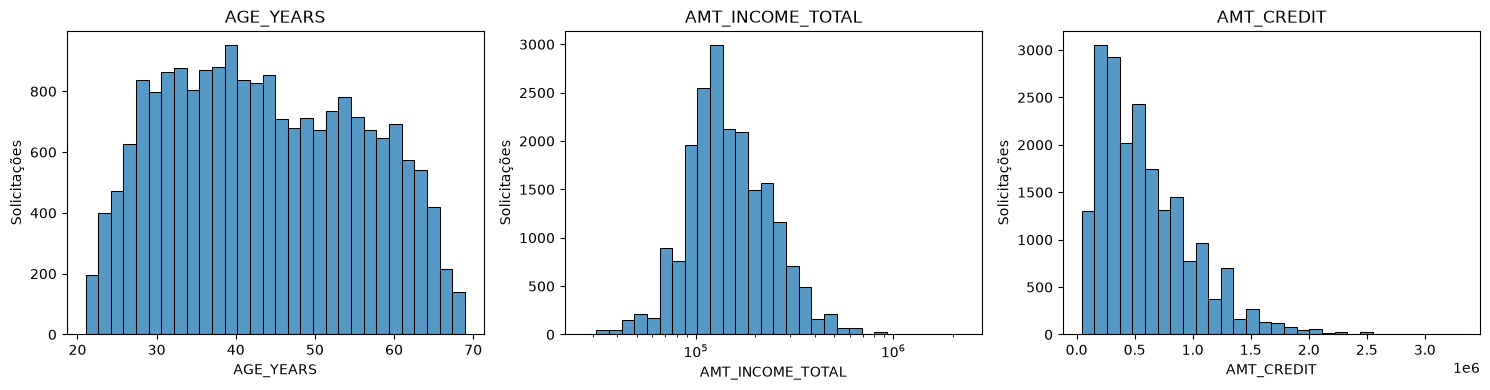

In [8]:
display(validator.describe_numeric(prepared_sample, preparation.numeric_features))
_ = reporter.plot_histograms(
    prepared_sample,
    ["AGE_YEARS", "AMT_INCOME_TOTAL", "AMT_CREDIT"],
    log_columns=["AMT_INCOME_TOTAL"],
)

## 7 Categorias e representatividade

Categorias pouco frequentes podem desaparecer na amostragem. Isso precisa
aparecer na interpretação: o baseline não demonstrará desempenho confiável
para todos os segmentos. Categorias novas serão toleradas pelo encoder,
mas deverão ser monitoradas como possível mudança de perfil.

In [9]:
display(
    validator.compare_categories(
        tables, preparation.categorical_features + preparation.binary_features
    )
)

,category,origem,amostra,column
0,Working,158774,10197,NAME_INCOME_TYPE
1,Commercial associate,71617,4710,NAME_INCOME_TYPE
2,Pensioner,55362,3623,NAME_INCOME_TYPE
3,State servant,21703,1464,NAME_INCOME_TYPE
4,Unemployed,22,1,NAME_INCOME_TYPE
5,Student,18,3,NAME_INCOME_TYPE
6,Businessman,10,1,NAME_INCOME_TYPE
7,Maternity leave,5,1,NAME_INCOME_TYPE
8,Secondary / secondary special,218391,14151,NAME_EDUCATION_TYPE
9,Higher education,74863,4856,NAME_EDUCATION_TYPE


## 8 Conclusão e passagem para o treinamento

A base representa solicitações com dificuldade de pagamento como classe
minoritária. Os próximos passos são converter idade e flags, manter uma
política explícita de ausências e separar os conjuntos antes de aprender
qualquer transformação.

Não há uma data de calendário que estabeleça períodos reais de produção.
O notebook 03 proporá janelas simuladas e explicará seus limites.
Idade, escolaridade e outras variáveis também exigirão discussão de vieses.

O diagnóstico abaixo deve ser revisado antes de continuar. Nenhum dado
tratado, modelo ou relatório de drift foi criado neste notebook.

In [10]:
display(validator.summarize(prepared_sample, "amostra_validada"))
display(
    validator.compare_targets({"amostra_validada": prepared_sample}, preparation.target)
)
print("Diagnóstico concluído. Dados apenas em memória; continue no notebook 02.")

,dataset,rows,columns,memory_mb
0,amostra_validada,20000,12,5.185859


,dataset,target,count,percent
0,amostra_validada,0,18385,91.925
1,amostra_validada,1,1615,8.075


Diagnóstico concluído. Dados apenas em memória; continue no notebook 02.
